In [1]:
import pandas as pd
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
ratings= pd.read_csv("u.data",
         sep="\t", 
         names=["user_id", "movie_id", "rating","timestamp"]
                    )

In [3]:
ratings.head()

,user_id,movie_id,rating,timestamp
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596


In [4]:
movies= pd.read_csv(
    "u.item",
    sep="|",
    encoding="latin-1",
    header=None,
    usecols=[0,1,2],
    names=["movie_id", "title", "release_date"]
)

In [5]:
movies.head()

,movie_id,title,release_date
0,1,Toy Story (1995),01-Jan-1995
1,2,GoldenEye (1995),01-Jan-1995
2,3,Four Rooms (1995),01-Jan-1995
3,4,Get Shorty (1995),01-Jan-1995
4,5,Copycat (1995),01-Jan-1995


In [6]:
data=pd.merge(
    ratings, 
    movies,
    on="movie_id",
    how="left"
    
)

In [7]:
data.head()

,user_id,movie_id,rating,timestamp,title,release_date
0,196,242,3,881250949,Kolya (1996),24-Jan-1997
1,186,302,3,891717742,L.A. Confidential (1997),01-Jan-1997
2,22,377,1,878887116,Heavyweights (1994),01-Jan-1994
3,244,51,2,880606923,Legends of the Fall (1994),01-Jan-1994
4,166,346,1,886397596,Jackie Brown (1997),01-Jan-1997


In [8]:
print("Rating shape:", ratings.shape)
print("movies shape:", movies.shape)
print("data shape:", data.shape)

Rating shape: (100000, 4)
movies shape: (1682, 3)
data shape: (100000, 6)


In [9]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 6 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   user_id       100000 non-null  int64 
 1   movie_id      100000 non-null  int64 
 2   rating        100000 non-null  int64 
 3   timestamp     100000 non-null  int64 
 4   title         100000 non-null  object
 5   release_date  99991 non-null   object
dtypes: int64(4), object(2)
memory usage: 4.6+ MB


In [10]:
data.describe(include="all")

,user_id,movie_id,rating,timestamp,title,release_date
count,100000.00000,100000.000000,100000.000000,1.000000e+05,100000,99991
unique,NaN,NaN,NaN,NaN,1664,240
top,NaN,NaN,NaN,NaN,Star Wars (1977),01-Jan-1995
freq,NaN,NaN,NaN,NaN,583,9932
mean,462.48475,425.530130,3.529860,8.835289e+08,NaN,NaN
std,266.61442,330.798356,1.125674,5.343856e+06,NaN,NaN
min,1.00000,1.000000,1.000000,8.747247e+08,NaN,NaN
25%,254.00000,175.000000,3.000000,8.794487e+08,NaN,NaN
50%,447.00000,322.000000,4.000000,8.828269e+08,NaN,NaN
75%,682.00000,631.000000,4.000000,8.882600e+08,NaN,NaN


In [11]:
data.isnull().sum().sort_values(ascending=False)

release_date    9
user_id         0
movie_id        0
rating          0
timestamp       0
title           0
dtype: int64

In [12]:
data.duplicated().sum()

np.int64(0)

In [13]:
print("unique users:", data["user_id"].nunique())
print("unique movies:",data["movie_id"].nunique())

unique users: 943
unique movies: 1682


In [14]:
print("Rating dostribution:")
ratings["rating"].value_counts().sort_index()

Rating dostribution:


rating
1     6110
2    11370
3    27145
4    34174
5    21201
Name: count, dtype: int64

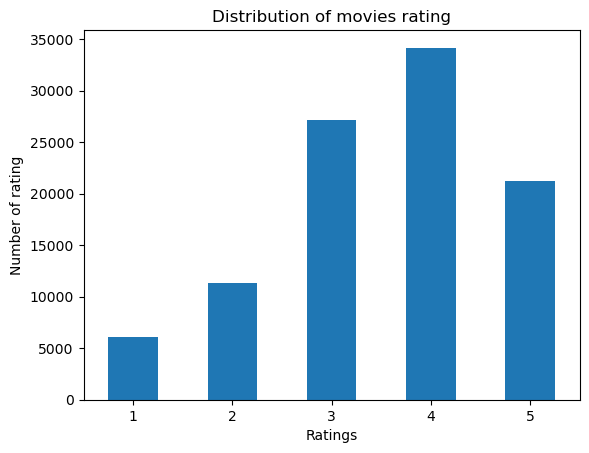

In [15]:
ratings["rating"].value_counts().sort_index().plot(kind="bar")
plt.title("Distribution of movies rating")
plt.xlabel("Ratings")
plt.ylabel("Number of rating")
plt.xticks(rotation=0)
plt.show()

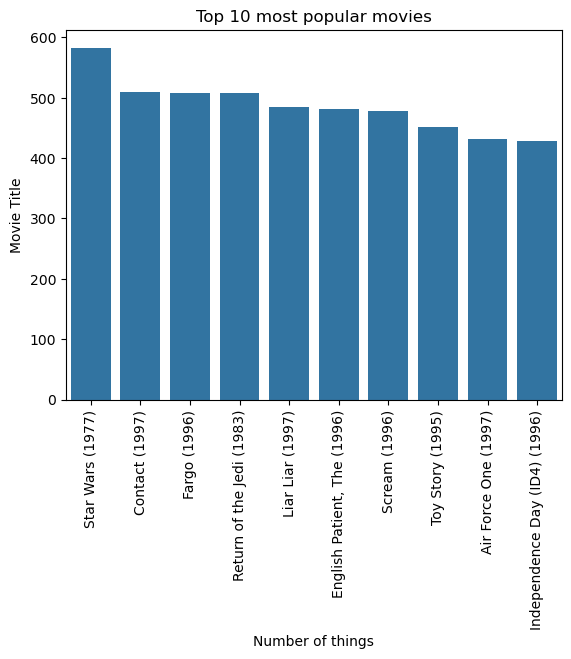

In [16]:
popular_movies=(
    data.groupby("title")["rating"].count().sort_values(ascending=False).head(10)
)
sns.barplot(popular_movies)
plt.title("Top 10 most popular movies")
plt.xlabel("Number of things")
plt.ylabel("Movie Title")
plt.xticks(rotation=90)
plt.show()

In [17]:
movie_ratings=(
    data.groupby("title")["rating"]
    .agg(["mean", "count"])
    .reset_index()
)
movie_ratings=movie_ratings[
    movie_ratings["count"]>=50
]
top_rated=movie_ratings.sort_values(
    "mean", ascending=False
).head(10)
top_rated

,title,mean,count
318,"Close Shave, A (1995)",4.491071,112
1281,Schindler's List (1993),4.466443,298
1652,"Wrong Trousers, The (1993)",4.466102,118
273,Casablanca (1942),4.456790,243
1597,Wallace & Gromit: The Best of Aardman Animatio...,4.447761,67
1317,"Shawshank Redemption, The (1994)",4.445230,283
1215,Rear Window (1954),4.387560,209
1572,"Usual Suspects, The (1995)",4.385768,267
1398,Star Wars (1977),4.358491,583
3,12 Angry Men (1957),4.344000,125


In [18]:
#keep only the columns required forr modeling
ratings_data=data[["user_id", "movie_id","rating"]].copy()
print("shape", ratings_data.shape)
display(ratings_data.head())

shape (100000, 3)


,user_id,movie_id,rating
0,196,242,3
1,186,302,3
2,22,377,1
3,244,51,2
4,166,346,1


In [19]:
from sklearn.model_selection import train_test_split
train_data, test_data=train_test_split(
    ratings_data,
    test_size=0.2,
    random_state=42
)
print("Training record:", len(train_data))
print("Testing_record:", len(test_data))

Training record: 80000
Testing_record: 20000


In [20]:
train_data

,user_id,movie_id,rating
75220,807,1411,1
48955,474,659,5
44966,463,268,4
13568,139,286,4
92727,621,751,4
...,...,...,...
6265,216,231,2
54886,343,276,5
76820,437,475,3
860,284,322,3


In [21]:
test_data

,user_id,movie_id,rating
75721,877,381,4
80184,815,602,3
19864,94,431,4
76699,416,875,2
92991,500,182,2
...,...,...,...
32595,72,591,5
29313,523,393,5
37862,606,287,4
53421,650,612,4


In [22]:
train_matrix=train_data.pivot_table(
    index="user_id",
    columns="movie_id",
    values="rating"
)
print("train_matrix", train_matrix.shape)
train_matrix.head()

train_matrix (943, 1653)


movie_id,1,2,3,4,5,6,7,8,9,10,...,1668,1670,1671,1672,1673,1676,1678,1679,1680,1681
user_id,,,,,,,,,,,,,,,,,,,,,
1,NaN,3.0,4.0,NaN,3.0,NaN,4.0,NaN,5.0,3.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [23]:
from sklearn.metrics.pairwise import cosine_similarity 
ratings_filled=train_matrix.fillna(0)
similarity_scores= cosine_similarity(ratings_filled.T)
item_similarity_df=pd.DataFrame(
    similarity_scores,
    index=train_matrix.columns,
    columns=train_matrix.columns
)
print("Similarity matrix shape:", item_similarity_df.shape)
item_similarity_df.head()

Similarity matrix shape: (1653, 1653)


movie_id,1,2,3,4,5,6,7,8,9,10,...,1668,1670,1671,1672,1673,1676,1678,1679,1680,1681
movie_id,,,,,,,,,,,,,,,,,,,,,
1,1.000000,0.311393,0.253690,0.350312,0.214229,0.081377,0.520601,0.376806,0.395321,0.208464,...,0.0,0.0,0.0,0.000000,0.040426,0.000000,0.0,0.0,0.0,0.000000
2,0.311393,1.000000,0.216764,0.383544,0.304612,0.000000,0.297186,0.308952,0.222845,0.121722,...,0.0,0.0,0.0,0.062446,0.000000,0.000000,0.0,0.0,0.0,0.088312
3,0.253690,0.216764,1.000000,0.261066,0.141570,0.058716,0.271301,0.167238,0.224092,0.120622,...,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.000000
4,0.350312,0.383544,0.261066,1.000000,0.270286,0.061803,0.366117,0.370546,0.265128,0.190169,...,0.0,0.0,0.0,0.043872,0.000000,0.103406,0.0,0.0,0.0,0.062044
5,0.214229,0.304612,0.141570,0.270286,1.000000,0.017833,0.246926,0.196619,0.199997,0.036237,...,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.000000


In [24]:
movie_id=train_matrix.columns[0]
similar_movies=(
    item_similarity_df[movie_id]
    .drop(movie_id)
    .sort_values(ascending=False)
    .head(5)
)
similar_movies=pd.DataFrame({
    "movie_id": similar_movies.index,
    "similarity_score": similar_movies.values
})
movie_titles=data.drop_duplicates("movie_id").set_index("movie_id")["title"]
similar_movies["title"]= similar_movies["movie_id"].map(movie_titles)
similar_movies= similar_movies[
    ["movie_id", "title", "similarity_score"
    
]]
print("Selected movie", movie_titles.loc[movie_id])
similar_movies

Selected movie Toy Story (1995)


,movie_id,title,similarity_score
0,50,Star Wars (1977),0.565169
1,181,Return of the Jedi (1983),0.542754
2,405,Mission: Impossible (1996),0.528257
3,151,Willy Wonka and the Chocolate Factory (1971),0.527215
4,7,Twelve Monkeys (1995),0.520601


In [25]:
global_mean= train_data["rating"].mean()
def predict_rating(user_id, movie_id):
    # handle unknown user or movies
    if user_id not in train_matrix.index:
        return global_mean
    if movie_id not in item_similarity_df.index:
        return global_mean
   # get movies this user rated in the training data
    user_ratings= train_matrix.loc[user_id].dropna()
   # get similarities betweeen the target movies and rated movies 
    similarities = item_similarity_df.loc[
        movie_id, user_ratings.index
    ]

   # keep only positive similar movies
    similarities=similarities[similarities>0]
    if similarities.empty:
        return global_mean
   # calculate similarity-weighted avarage 
    ratings= user_ratings.loc[similarities.index]
    prediction=(
        (similarities*ratings).sum()
        / similarities.abs().sum()
    )
    return prediction
    

In [26]:

sample = test_data.iloc[0]

actual_rating = sample["rating"]

predicted_rating = predict_rating(
    sample["user_id"],
    sample["movie_id"]
)

print("User ID:", sample["user_id"])
print("Movie ID:", sample["movie_id"])
print("Actual rating:", actual_rating)
print("Predicted rating:", round(predicted_rating, 2))


User ID: 877
Movie ID: 381
Actual rating: 4
Predicted rating: 3.74


In [27]:

from sklearn.metrics import mean_absolute_error, mean_squared_error

y_true = test_data["rating"].to_numpy()

y_pred = np.array([
    predict_rating(row.user_id, row.movie_id)
    for row in test_data.itertuples(index=False)
])

mae = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))

print("Item-Based Collaborative Filtering")
print("MAE:", round(mae, 3))
print("RMSE:", round(rmse, 3))


Item-Based Collaborative Filtering
MAE: 0.808
RMSE: 1.014


In [28]:

def recommend_movies(user_id, n=10):
    if user_id not in train_matrix.index:
        return pd.DataFrame(
            columns=["movie_id", "title", "predicted_rating"]
        )

    watching_movies = set(
        train_matrix.loc[user_id].dropna().index
    )

    unseen_movies = [
        movie_id for movie_id in train_matrix.columns
        if movie_id not in watching_movies
    ]

    predictions = [
        (movie_id, predict_rating(user_id, movie_id))
        for movie_id in unseen_movies
    ]

    predictions.sort(key=lambda x: x[1], reverse=True)
    top_predictions = predictions[:n]

    movie_titles = (
        data.drop_duplicates("movie_id")
        .set_index("movie_id")["title"]
    )

    recommendations = pd.DataFrame(
        top_predictions,
        columns=["movie_id", "predicted_rating"]
    )

    recommendations["title"] = recommendations["movie_id"].map(
        movie_titles
    )

    return recommendations[
        ["movie_id", "title", "predicted_rating"]
    ].reset_index(drop=True)


In [29]:
user_id= int(train_matrix.index[10])
recommendations=recommend_movies(user_id, n=10)
print("Recommendation for user:", user_id)
recommendations

Recommendation for user: 11


,movie_id,title,predicted_rating
0,1235,"Big Bang Theory, The (1994)",5.000000
1,1236,"Other Voices, Other Rooms (1997)",5.000000
2,1653,Entertaining Angels: The Dorothy Day Story (1996),4.333775
3,314,3 Ninjas: High Noon At Mega Mountain (1998),4.194364
4,1656,Little City (1998),4.128774
5,1080,Celestial Clockwork (1994),3.936090
6,1624,Hush (1998),3.903421
7,1625,Nightwatch (1997),3.903421
8,1658,"Substance of Fire, The (1996)",3.893094
9,1642,Some Mother's Son (1996),3.874714


In [33]:
import joblib
import os
os.makedirs("movie_recommender", exist_ok=True)
joblib.dump(item_similarity_df, "movie_recommender/item_similarity.pkl")
joblib.dump(train_matrix, "movie_recommender/train_matrix.pkl")
joblib.dump(train_data["rating"].mean(), "movie_recommender/global_mean.pkl")
movie_info = (data.drop_duplicates("movie_id")[["movie_id","title"]])
movie_info.to_csv("movie_recommender/movie_info.csv", index=False)
print("Model artifacts saved successfully")

Model artifacts saved successfully


In [34]:
import shutil
shutil.make_archive("movie_recommender", "zip", ".", "movie_recommender")

'C:\\Users\\Lenovo\\Desktop\\prime classes\\Machine Learning\\minor_project\\movie_recommender.zip'

In [36]:
import zipfile
import os

zip_path = r"C:\Users\Lenovo\Desktop\prime classes\Machine Learning\minor_project\movie_recommender.zip"

extract_path = r"C:\Users\Lenovo\Desktop\prime classes\Machine Learning\minor_project\movie_recommender"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("ZIP file successfully extracted!")

ZIP file successfully extracted!
